In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# Load your block RDFs
files = [
    'rdf0.xvg',
    'rdf1.xvg',
    'rdf2.xvg',
    'rdf3.xvg',
    'rdf4.xvg'
]


def load_xvg(f):
    return np.loadtxt(f, comments=['#', '@'])


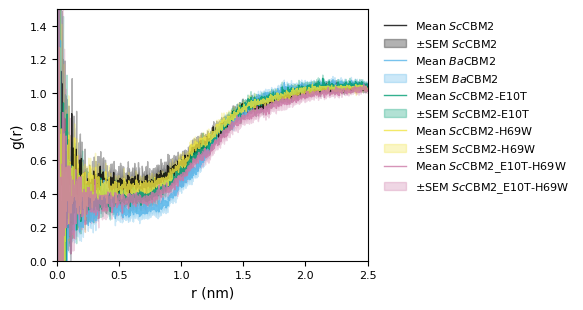

In [4]:
plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 8,  # legend
})

colors = ["k", "#56B5E9", "#009E73", "#F0E442", "#CC79A7"]
targets = ['ScCBM2', 'BaCBM2', 'ScCBM2_E272T', 'ScCBM2_H331W', 'ScCBM2_double']
labels = [r'$\mathit{Sc}$CBM2', r'$\mathit{Ba}$CBM2', r'$\mathit{Sc}$CBM2-E10T', r'$\mathit{Sc}$CBM2-H69W', r'$\mathit{Sc}$CBM2_E10T-H69W']


width_mm = 150
width_in = width_mm / 25.4 
height_in = 80 / 25.4

fig, ax = plt.subplots(figsize=(width_in,height_in))
for t, color, l in zip(targets, colors, labels):
#for t in ['ScCBM2', 'BaCBM2', 'ScCBM2_E272T']:    
    data = [load_xvg(f'{t}/{f}') for f in files]
    # Find common r range
    #r_min = max(d[:, 0].min() for d in data)
    #r_max = min(d[:, 0].max() for d in data)
    
    # Create common grid
    #r_common = np.linspace(r_min, r_max, 500)
    
    # Interpolate all RDFs onto common grid
    #gr_interp = []
    #for d in data:
    #    f = interp1d(d[:, 0], d[:, 1], kind='linear')
    #    gr_interp.append(f(r_common))

    r = np.array(data[0][:,0])
    gr_all = np.array([d[:,1] for d in data])
    
    # Calculate statistics
    gr_mean = gr_all.mean(axis=0)
    gr_std = gr_all.std(axis=0, ddof=1)
    gr_sem = gr_std / np.sqrt(len(files))
    

    ax.plot(r, gr_mean, color = color, alpha=0.8, lw=1, label=f'Mean {l}')
    ax.fill_between(r, gr_mean - gr_sem, gr_mean + gr_sem, alpha=0.3, color = color, label=f'±SEM {l}')
ax.set_ylim(0,1.5)
ax.set_xlim(0,2.5)
ax.set_xlabel('r (nm)')
ax.set_ylabel('g(r)')
ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 1), frameon = False
)
plt.tight_layout()
plt.savefig('rdf_block_averaged.png', dpi=600)
plt.show()


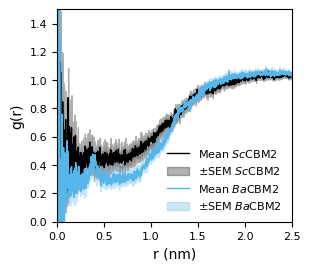

In [8]:
plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 8,  # legend
})

colors = ["k", "#56B5E9"]
targets = ['ScCBM2', 'BaCBM2']


width_mm = 80
width_in = width_mm / 25.4 
height_in = 70 / 25.4 

fig, ax = plt.subplots(figsize=(width_in, height_in ))
for t, color in zip(targets, colors):
#for t in ['ScCBM2', 'BaCBM2', 'ScCBM2_E272T']:    
    data = [load_xvg(f'{t}/{f}') for f in files]
    # Find common r range
    #r_min = max(d[:, 0].min() for d in data)
    #r_max = min(d[:, 0].max() for d in data)
    
    # Create common grid
    #r_common = np.linspace(r_min, r_max, 500)
    
    # Interpolate all RDFs onto common grid
    #gr_interp = []
    #for d in data:
    #    f = interp1d(d[:, 0], d[:, 1], kind='linear')
    #    gr_interp.append(f(r_common))

    r = np.array(data[0][:,0])
    gr_all = np.array([d[:,1] for d in data])
    
    # Calculate statistics
    gr_mean = gr_all.mean(axis=0)
    gr_std = gr_all.std(axis=0, ddof=1)
    gr_sem = gr_std / np.sqrt(len(files))
    
    if 'Ba' in t:
        t = r'$\mathit{Ba}$CBM2'
    else:
        t = r'$\mathit{Sc}$CBM2'
    
    ax.plot(r, gr_mean, color = color, lw=1, label=f'Mean {t}')
    ax.fill_between(r, gr_mean - gr_sem, gr_mean + gr_sem, alpha=0.3, color = color, label=f'±SEM {t}')
ax.set_ylim(0,1.5)
ax.set_xlim(0,2.5)
ax.set_xlabel('r (nm)')
ax.set_ylabel('g(r)')
plt.legend(loc = 'lower right',frameon = False)
plt.tight_layout()
plt.savefig('rdf_block_averaged_BaSc.png', dpi=600)
plt.savefig('rdf_block_averaged_BaSc.svg', bbox_inches='tight')
plt.show()
